In [1]:
import os
import glob
import re
from collections import defaultdict
 
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
# zone géographique
lon_min, lon_max = -65, -55
lat_min, lat_max = 34, 42
 
ssh_var = 'ssh_corr'

# données
swot_dir = '/data1/data/obs/level3/SWOT/V-3/'
 
nst_dirs = {
    "SSH + SST": "/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH-SST_Azo",
    "SSH seul": "/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH_Azo"
}
 
# période pour le calcul annuel
jours = pd.date_range("2024-01-01", "2024-12-31")

In [52]:
# ---------- paramètres ----------
date = pd.Timestamp("2024-02-10")      # jour de la carte NeurOST
d = 15                                 # demi-fenêtre utilisée pour ce run
cmems_dir = "/home/nora/projects/NeurOST/input_data/cmems_sla"

# ---------- lecture des traces swon sur la fenêtre ----------
lon_nad = []
lat_nad = []
ecart_nad = []          # écart en jours au jour de la carte

for k in range(-d, d + 1):
    jour = date + pd.Timedelta(days=k)
    # TODO : adapter le motif au nom de tes fichiers swon
    fichiers = sorted(glob.glob(f"{cmems_dir}/swon/dt_global_swon_phy_l3_1hz_{jour:%Y%m%d}_*.nc"))
    for fn in fichiers:
        tr = xr.open_dataset(fn)
        #print(tr)
        lo = (tr.longitude.values + 180) % 360 - 180
        la = tr.latitude.values
        dans_boite = (lo > lon_min) & (lo < lon_max) & (la > lat_min) & (la < lat_max)
        lon_nad.extend(lo[dans_boite])
        lat_nad.extend(la[dans_boite])
        ecart_nad.extend([k] * int(dans_boite.sum()))
        tr.close()

print(len(lon_nad), "points nadir swon dans la boîte")

3117 points nadir swon dans la boîte


1. Exploration d'un jour 

In [53]:
# choix de la date
 
date = '20240210'

In [54]:
# sélection des fichiers SWOT
 
# 1. fichiers dont le nom contient la date (à vérifier avec un ls)
files = sorted(glob.glob(f"{swot_dir}/*{date}T*.nc"))
print(len(files), "fichiers pour", date)
 
# 2. on garde ceux qui passent dans la zone
swot_files = []
for f in files:
    ds = xr.open_dataset(f)
    ds['ssh_corr'] = (ds['ssha_unfiltered']
                    - ds['LongWavelenghtError_cnst_swot_karin']
                    - ds['LongWavelenghtError_lin_swot_karin'])
    lon = ((ds["longitude"] + 180) % 360 - 180).values   # ramené en [-180, 180]
    lat = ds["latitude"].values
    in_box = (lon >= lon_min) & (lon <= lon_max) & (lat >= lat_min) & (lat <= lat_max)
    if in_box.any():
        swot_files.append(f)
        print("OK :", f.split("/")[-1], "-", int(in_box.sum()), "points dans la zone")
    ds.close()
 
print(len(swot_files), "fichiers sélectionnés")

29 fichiers pour 20240210
OK : SWOT_L3_LR_SSH_Expert_010_451_20240210T021041_20240210T030208_v3.0.nc - 31399 points dans la zone
OK : SWOT_L3_LR_SSH_Expert_010_464_20240210T131930_20240210T141057_v3.0.nc - 31399 points dans la zone
2 fichiers sélectionnés


In [55]:
# ouverture file NeurOST
 
neurost_file = f"/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH_GS_swon_0j/NeurOST_SSH_GS_swon_0j_L250km_20240210_20261117.nc"
nst = xr.open_dataset(neurost_file).isel(time=0)

-0.02232687421302965 0.08367438633457419
SWOT_L3_LR_SSH_Expert_010_476_20240210T233652_20240211T002819_v3.0.nc rmse=0.087


/tmp/ipykernel_422194/3077711895.py:40: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im = ax.pcolormesh(lon, lat, dd, cmap=cmap, vmin=vmin, vmax=vmax)


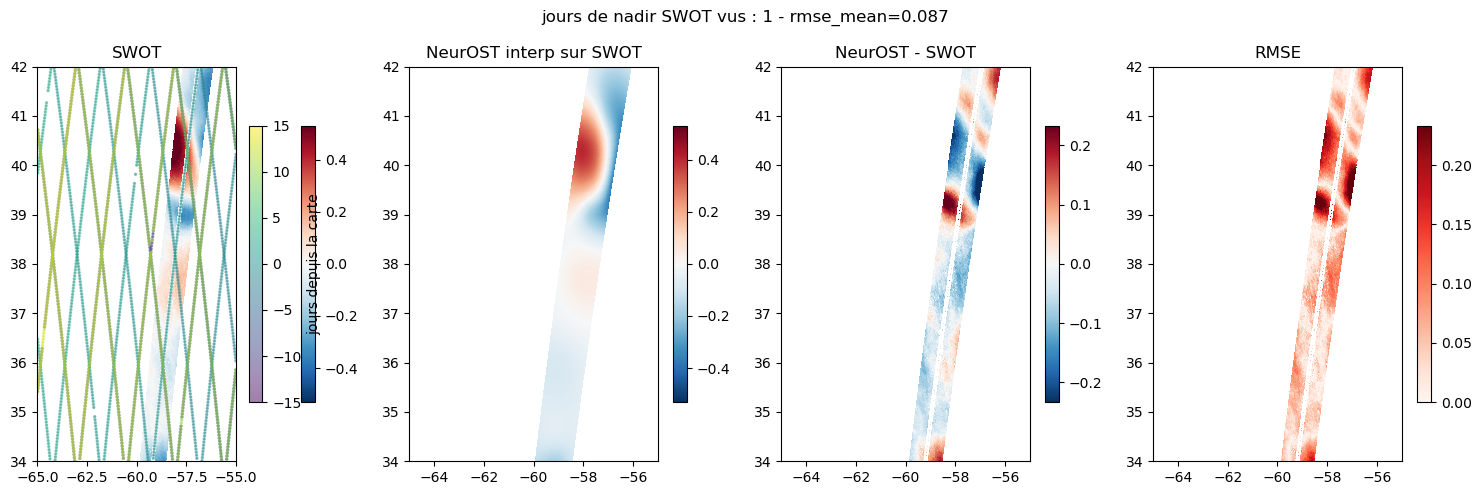

In [56]:
# PLOT
 
fig, axes = plt.subplots(1, 4, figsize=(15, 5), squeeze=False)
ds = xr.open_dataset(swot_files[0])

ds['ssh_corr'] = (ds['ssha_unfiltered']
                - ds['LongWavelenghtError_cnst_swot_karin']
                - ds['LongWavelenghtError_lin_swot_karin'])

lon = (ds.longitude + 180) % 360 - 180
lat = ds.latitude
box = (lon > lon_min) & (lon < lon_max) & (lat > lat_min) & (lat < lat_max)

swot = ds['ssh_corr'].where(box)
# NeurOST est en 0-360
neurost = nst.sla.interp(longitude=(ds.longitude % 360).where(box), latitude=lat.where(box))
diff = neurost - swot
rmse = np.sqrt(diff**2)
print (diff.mean().values, diff.std().values)
rmse_mean = float(np.sqrt((diff**2).mean()))
print(f.split("/")[-1], f"rmse={rmse_mean:.3f}")
 
v_ssh = float(np.nanpercentile(np.abs(swot), 98))
v_diff = float(np.nanpercentile(np.abs(diff), 98))
v_rmse = float(np.nanpercentile(np.abs(rmse), 98))


    #for ax, d, title, v in zip(row, [swot, neurost, diff],
     #                       ["SWOT", "NeurOST interp sur SWOT", "NeurOST - SWOT"],
     #                       [v_ssh, v_ssh, v_diff]):


cmaps = ["RdBu_r", "RdBu_r", "RdBu_r", "Reds"]
vmins = [-v_ssh, -v_ssh, -v_diff, 0]
vmaxs = [v_ssh, v_ssh, v_diff, v_rmse]
titles = ["SWOT", "NeurOST interp sur SWOT", "NeurOST - SWOT", "RMSE"]

for i, (ax, dd, title, cmap, vmin, vmax) in enumerate(zip(axes[0], [swot, neurost, diff, rmse],
                                                          titles, cmaps, vmins, vmaxs)):
    im = ax.pcolormesh(lon, lat, dd, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xlim(lon_min, lon_max)
    ax.set_ylim(lat_min, lat_max)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.7)

    if i == 0:      # premier panneau : on ajoute les traces nadir
        sc = ax.scatter(lon_nad, lat_nad, c=ecart_nad, cmap="viridis", alpha=0.5,
                        vmin=-max(d, 1), vmax=max(d, 1), s=2)
        fig.colorbar(sc, ax=ax, shrink=0.7, label="jours depuis la carte")

fig.suptitle(f'jours de nadir SWOT vus : 1 - rmse_mean={rmse_mean:.3f}')
plt.tight_layout()

2. RMSE journalier sur l'année

In [7]:
# --------------------------------------------------
# Indexation des fichiers
# --------------------------------------------------
 
def indexer_nst(dossier):
    fichiers = defaultdict(list)
 
    for f in glob.glob(os.path.join(dossier, "*.nc")):
        match = re.search(r"_(\d{8})_", os.path.basename(f))
        if match:
            fichiers[match.group(1)].append(f)
 
    return fichiers
 
 
def indexer_swot(dossier):
    fichiers = defaultdict(list)
 
    for f in glob.glob(os.path.join(dossier, "*.nc")):
        match = re.search(r"_(\d{8})T", os.path.basename(f))
        if match:
            fichiers[match.group(1)].append(f)
 
    return fichiers

In [8]:
# --------------------------------------------------
# Calcul des RMSE
# --------------------------------------------------
 
def calcul_rmse(nst_dirs, swot_dir):
 
    nst_index = {
        nom: indexer_nst(dossier)
        for nom, dossier in nst_dirs.items()
    }
 
    swot_index = indexer_swot(swot_dir)
 
    rmse = {nom: [] for nom in nst_dirs}
 
    for jour in jours:
 
        d = jour.strftime("%Y%m%d")
 
        # Réinitialisation quotidienne
        somme_jour = {nom: 0.0 for nom in nst_dirs}
        compte_jour = {nom: 0 for nom in nst_dirs}
 
        # Vérifier la présence des cartes NeurOST
        cartes = {}
 
        for nom in nst_dirs:
            fichiers = sorted(nst_index[nom][d])
 
            if fichiers:
                cartes[nom] = xr.open_dataset(fichiers[-1])
 
        # Vérifier la présence des fichiers SWOT
        fichiers_swot = sorted(swot_index[d])
 
        if not cartes or not fichiers_swot:
            for nom in nst_dirs:
                rmse[nom].append(np.nan)
 
            for ds in cartes.values():
                ds.close()
 
            continue
 
        # Charger les cartes NeurOST une seule fois
        cartes_chargees = {}
 
        for nom, ds in cartes.items():
            cartes_chargees[nom] = ds.isel(time=0).load()
 
        # Parcours des fichiers SWOT du jour
        for f in fichiers_swot:
 
            with xr.open_dataset(f) as ds:

                ds['ssh_corr'] = (ds['ssha_unfiltered']
                                    - ds['LongWavelenghtError_cnst_swot_karin']
                                    - ds['LongWavelenghtError_lin_swot_karin'])
 
                lon = ds.longitude.values
                lat = ds.latitude.values
                swot = ds['ssh_corr'].values
 
                # Masque spatial
                lon_norm = (lon + 180) % 360 - 180
 
                mask = (
                    (lon_norm > lon_min) &
                    (lon_norm < lon_max) &
                    (lat > lat_min) &
                    (lat < lat_max) &
                    np.isfinite(swot)
                )
 
                if not mask.any():
                    continue
 
                # Coordonnées des seuls points SWOT utiles
                lon_pts = (lon[mask] % 360)
                lat_pts = lat[mask]
                swot_pts = swot[mask]
 
                lon_interp = xr.DataArray(lon_pts, dims="points")
                lat_interp = xr.DataArray(lat_pts, dims="points")
 
                # Comparaison avec chaque configuration NeurOST
                for nom, nst in cartes_chargees.items():
 
                    nn = nst.sla.interp(
                        longitude=lon_interp,
                        latitude=lat_interp
                    ).values
 
                    diff = nn - swot_pts
 
                    valid = np.isfinite(diff)
 
                    somme_jour[nom] += np.sum(diff[valid]**2)
                    compte_jour[nom] += valid.sum()
 
        # Fermeture des datasets
        for ds in cartes.values():
            ds.close()
 
        # RMSE journalier
        for nom in nst_dirs:
 
            n = compte_jour[nom]
 
            valeur = (
                np.sqrt(somme_jour[nom] / n)
                if n > 0 else np.nan
            )
 
            rmse[nom].append(valeur)
 
        print(
            d,
            " | ".join(
                f"{nom}: {rmse[nom][-1]:.4f}"
                if np.isfinite(rmse[nom][-1])
                else f"{nom}: NaN"
                for nom in nst_dirs
            )
        )
 
    return {nom: np.array(val) for nom, val in rmse.items()}

In [10]:
# --------------------------------------------------
# Exécution + sauvegarde
# --------------------------------------------------
 
resultats = calcul_rmse(nst_dirs, swot_dir)
 
df = pd.DataFrame({
    "date": jours,
    "RMSE_SSH_SST": resultats["SSH + SST"],
    "RMSE_SSH": resultats["SSH seul"]
})
 
df.to_csv("/home/nora/projects/NeurOST/my_work/files/RMSE_NeurOST_Azo_2024.csv", index=False)

20240104 SSH + SST: NaN | SSH seul: NaN
20240105 SSH + SST: NaN | SSH seul: NaN
20240106 SSH + SST: 0.0177 | SSH seul: 0.0192
20240107 SSH + SST: 0.0199 | SSH seul: 0.0201
20240108 SSH + SST: 0.0300 | SSH seul: 0.0295
20240109 SSH + SST: 0.0247 | SSH seul: 0.0251
20240110 SSH + SST: NaN | SSH seul: NaN
20240111 SSH + SST: NaN | SSH seul: NaN
20240112 SSH + SST: NaN | SSH seul: NaN
20240113 SSH + SST: NaN | SSH seul: NaN
20240114 SSH + SST: NaN | SSH seul: NaN
20240115 SSH + SST: NaN | SSH seul: NaN
20240116 SSH + SST: 0.0200 | SSH seul: 0.0225
20240117 SSH + SST: 0.0176 | SSH seul: 0.0188
20240118 SSH + SST: 0.0175 | SSH seul: 0.0188
20240119 SSH + SST: 0.0168 | SSH seul: 0.0169
20240120 SSH + SST: 0.0161 | SSH seul: 0.0167
20240121 SSH + SST: NaN | SSH seul: NaN
20240122 SSH + SST: NaN | SSH seul: NaN
20240123 SSH + SST: NaN | SSH seul: NaN
20240124 SSH + SST: NaN | SSH seul: NaN
20240125 SSH + SST: NaN | SSH seul: NaN
20240126 SSH + SST: NaN | SSH seul: NaN
20240127 SSH + SST: 0.0186

3. Visualisation

In [11]:
# relecture du CSV (parse_dates pour que l'axe x soit reconnu comme des dates)
 
df_azo = pd.read_csv("/home/nora/projects/NeurOST/my_work/files/RMSE_NeurOST_Azo_2024.csv", parse_dates=["date"])
 
rmse_sst_mean_azo = df_azo["RMSE_SSH_SST"].mean()   # les NaN sont ignorés
rmse_ssh_mean_azo = df_azo["RMSE_SSH"].mean()

df_gs = pd.read_csv("/home/nora/projects/NeurOST/my_work/files/RMSE_NeurOST_GulfStream_2024.csv", parse_dates=["date"])

rmse_sst_mean_gs = df_gs["RMSE_SSH_SST"].mean()   # les NaN sont ignorés
rmse_ssh_mean_gs = df_gs["RMSE_SSH"].mean()

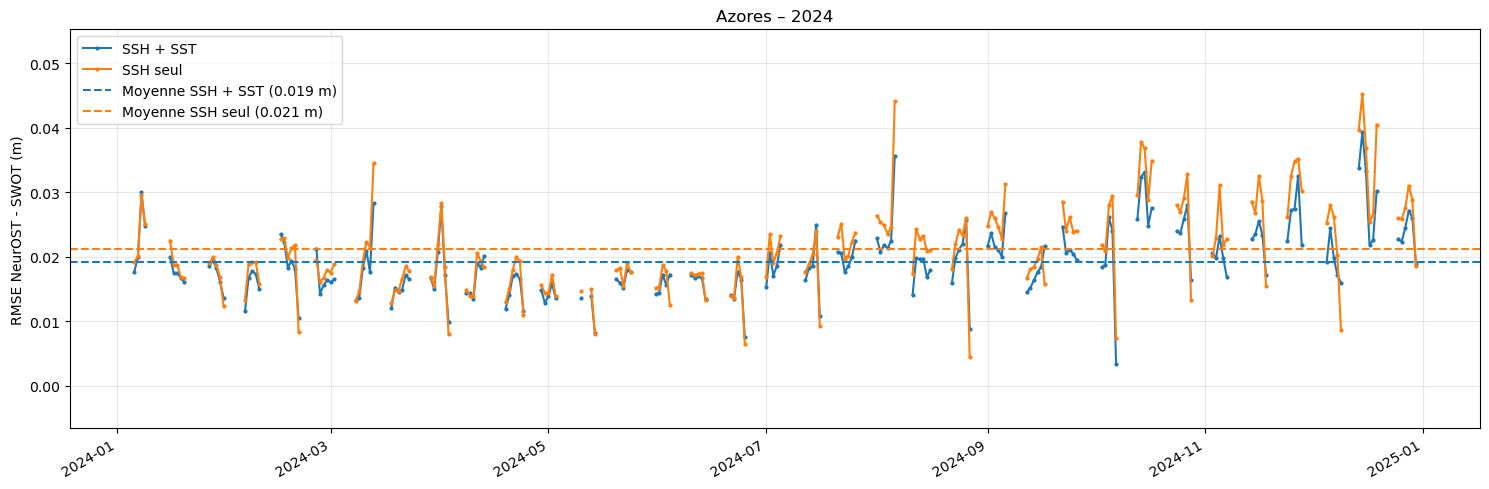

In [12]:
fig, ax = plt.subplots(figsize=(15, 5))
 
ax.plot(df_azo["date"], df_azo["RMSE_SSH_SST"], "o-", markersize=2, color='tab:blue', label="SSH + SST")
ax.plot(df_azo["date"], df_azo["RMSE_SSH"], "o-", markersize=2, color='tab:orange', label="SSH seul")
ax.axhline(rmse_sst_mean_azo, color='tab:blue', linestyle='--', label=f'Moyenne SSH + SST ({rmse_sst_mean_azo:.3f} m)')
ax.axhline(rmse_ssh_mean_azo, color='tab:orange', linestyle='--', label=f'Moyenne SSH seul ({rmse_ssh_mean_azo:.3f} m)')

ax.set_ylim(df_azo[["RMSE_SSH_SST", "RMSE_SSH"]].min().min() - 0.01, df_azo[["RMSE_SSH_SST", "RMSE_SSH"]].max().max() + 0.01)
 
ax.set_ylabel("RMSE NeurOST - SWOT (m)")
ax.set_title("Azores – 2024")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
plt.savefig("rmse_2024.png", dpi=150)
plt.show()